# 05. 유저 서버 로그 시퀀스(`seq`) 분석 및 GBDT 조인용 경량 요약 피처 추출

이 노트북은 분리 저장된 `train_seq.parquet`(10,704,179행) 및 `test_seq.parquet`(1,527,298행)을 **OOM 없이 PyArrow 배치 스트리밍**으로 처리해 다음 두 가지 목표를 달성합니다.

1. **시퀀스 구조 프로파일링**: 구분자 자동 감지(`detect_seq_delimiter`), 빈 시퀀스(`None`/`NaN`/`""`) 비율, 시퀀스 길이 분포 분위수(p50/p90/p95/p99/max) 파악
2. **Track A (GBDT 지원용 경량 피처) 산출**: `train_seq_summary.parquet` 및 `test_seq_summary.parquet` 생성
   - 11종 요약 피처: `seq_is_empty`, `seq_char_len`, `seq_token_len`, `seq_unique_cnt`, `seq_unique_ratio`, `seq_last_1`, `seq_last_2`, `seq_last_3`, `seq_first_1`, `seq_top1_share`, `seq_recent5_unique_ratio`
   - 타겟 누수 0%: 오직 해당 행의 `seq` 문자열만으로 결정론적 `int32` 해시 ID 및 통계를 추출합니다.

In [1]:
from google.colab import drive
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

import os as _os
if not _os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

# TODO: Google Drive 내 프로젝트 루트 경로에 맞게 수정하세요.
PROJECT_ROOT = Path('/content/drive/MyDrive/toss_ctr')
if (PROJECT_ROOT / 'src').exists() and str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
if (PROJECT_ROOT / 'pyproject.toml').exists():
    os.chdir(PROJECT_ROOT)
    %pip install -e . --no-deps --quiet

from toss_ctr.features.seq_features import (
    SEQ_SUMMARY_FEATURE_COLS,
    detect_seq_delimiter,
    extract_seq_summary_parquet,
    parse_seq_string,
)

cfg_path = PROJECT_ROOT / 'configs' / 'deep_seq_dcn.yaml'
with open(cfg_path, 'r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

train_seq_path = Path(cfg['paths']['train_seq'])
test_seq_path = Path(cfg['paths']['test_seq'])
train_tab_path = Path(cfg['paths']['train_tabular'])
train_summary_out = Path(cfg['paths']['train_seq_summary'])
test_summary_out = Path(cfg['paths']['test_seq_summary'])
report_dir = Path(cfg['paths']['report_dir'])
report_dir.mkdir(parents=True, exist_ok=True)

print('Train seq:', train_seq_path, '| exists:', train_seq_path.exists())
print('Test  seq:', test_seq_path, '| exists:', test_seq_path.exists())
print('요약 피처 11종:', SEQ_SUMMARY_FEATURE_COLS)

  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done


  Building editable for toss-ctr (pyproject.toml) ... done


Train seq: /content/work/model_data/train_seq.parquet | exists: True
Test  seq: /content/work/model_data/test_seq.parquet | exists: True
요약 피처 11종: ('seq_is_empty', 'seq_char_len', 'seq_token_len', 'seq_unique_cnt', 'seq_unique_ratio', 'seq_last_1', 'seq_last_2', 'seq_last_3', 'seq_first_1', 'seq_top1_share', 'seq_recent5_unique_ratio')


### [해석 1] Google Drive 마운트, 패키지 연결 및 설정 로드 확인
- `configs/deep_seq_dcn.yaml`에서 분리된 시퀀스 아티팩트 경로(`train_seq.parquet`, `test_seq.parquet`)와 출력 경로(`train_seq_summary.parquet`, `test_seq_summary.parquet`)를 불러왔습니다.
- `toss_ctr.features.seq_features` 모듈을 editable 모드로 연결해 본선 코드 검증과 동일한 스트리밍 추출 로직을 사용합니다.

In [2]:
# 1) Parquet 메타데이터 조회 및 앞부분 샘플로 구분자/포맷 확인 (메모리 부담 ~0MB)
tr_pf = pq.ParquetFile(train_seq_path)
te_pf = pq.ParquetFile(test_seq_path)
print(f'train_seq rows: {tr_pf.metadata.num_rows:,}, row_groups: {tr_pf.metadata.num_row_groups}')
print(f'test_seq  rows: {te_pf.metadata.num_rows:,}, row_groups: {te_pf.metadata.num_row_groups}')

sample_tr = next(tr_pf.iter_batches(batch_size=5000, columns=['row_id', 'seq'])).to_pandas()
sample_te = next(te_pf.iter_batches(batch_size=5000, columns=['ID', 'seq'])).to_pandas()

tr_delim = detect_seq_delimiter(sample_tr['seq'])
te_delim = detect_seq_delimiter(sample_te['seq'])
print(f'자동 감지된 구분자 - Train: {tr_delim!r}, Test: {te_delim!r}')

for i in range(5):
    raw_s = sample_tr['seq'].iloc[i]
    toks = parse_seq_string(raw_s, delimiter=tr_delim)
    preview = str(raw_s)[:60] + ('...' if raw_s and len(str(raw_s)) > 60 else '')
    print(f'  Sample[{i}] len={len(toks):>4} | raw={preview!r} | last_3={toks[-3:]}')

train_seq rows: 1,225,074, row_groups: 13
test_seq  rows: 1,527,298, row_groups: 16


자동 감지된 구분자 - Train: ',', Test: ','
  Sample[0] len=1018 | raw='9,18,269,516,57,97,527,74,317,311,269,479,57,74,317,77,58,58...' | last_3=['338', '479', '35']
  Sample[1] len= 336 | raw='144,269,57,516,35,479,57,516,527,74,77,318,193,463,212,151,3...' | last_3=['74', '35', '479']
  Sample[2] len= 837 | raw='9,516,57,527,74,77,532,101,132,138,101,101,132,101,497,532,1...' | last_3=['74', '35', '479']
  Sample[3] len= 466 | raw='9,516,57,221,97,63,520,426,221,426,97,516,227,165,417,97,121...' | last_3=['479', '35', '479']
  Sample[4] len=  53 | raw='516,57,195,27,27,516,74,527,318,317,77,75,269,15,75,483,269,...' | last_3=['74', '479', '35']


### [해석 2] 시퀀스 구분자 자동 감지 및 원시 로그 파싱 스모크 점검
- 전체 데이터를 적재하지 않고 첫 5,000행 배치만 읽어 `detect_seq_delimiter()`로 구분자를 확인하고, Train/Test 포맷 일관성을 점검했습니다.
- `parse_seq_string()`은 결측치(`None`, `NaN`) 및 빈 문자열을 빈 리스트 `[]`로 안전하게 정규화하며, 마지막 최근 토큰(`toks[-3:]`)이 최신 행동 로그임을 확인합니다.

In [3]:
# 2) Train / Test 시퀀스 요약 피처 스트리밍 추출 실행
t0 = time.perf_counter()
train_stats = extract_seq_summary_parquet(
    seq_parquet_path=train_seq_path,
    output_path=train_summary_out,
    id_col='row_id',
    seq_col='seq',
    delimiter=cfg['seq']['delimiter'],
    batch_size=cfg['seq']['summary_batch_size'],
    compression=cfg['seq']['compression'],
    compression_level=cfg['seq'].get('compression_level'),
)
print(f'Train seq 요약 추출 완료 ({time.perf_counter() - t0:.1f}s):')
display(pd.Series(train_stats))

t1 = time.perf_counter()
test_stats = extract_seq_summary_parquet(
    seq_parquet_path=test_seq_path,
    output_path=test_summary_out,
    id_col='ID',
    seq_col='seq',
    delimiter=cfg['seq']['delimiter'],
    batch_size=cfg['seq']['summary_batch_size'],
    compression=cfg['seq']['compression'],
    compression_level=cfg['seq'].get('compression_level'),
)
print(f'Test seq 요약 추출 완료 ({time.perf_counter() - t1:.1f}s):')
display(pd.Series(test_stats))

stats_path = report_dir / 'seq_summary_stats.json'
with open(stats_path, 'w', encoding='utf-8') as f:
    json.dump({'train': train_stats, 'test': test_stats}, f, ensure_ascii=False, indent=2)
print('통계 리포트 저장 완료:', stats_path)

Train seq 요약 추출 완료 (163.6s):


,0
source_path,/content/work/model_data/train_seq.parquet
output_path,/content/work/model_data/train_seq_summary.par...
id_col,row_id
rows,1225074
empty_rows,0
empty_ratio,0.0
mean_token_len,520.4929
p50_token_len,426.0
p90_token_len,1116.0
p95_token_len,1336.0


Test seq 요약 추출 완료 (213.3s):


,0
source_path,/content/work/model_data/test_seq.parquet
output_path,/content/work/model_data/test_seq_summary.parquet
id_col,ID
rows,1527298
empty_rows,0
empty_ratio,0.0
mean_token_len,542.1629
p50_token_len,453.0
p90_token_len,1135.0
p95_token_len,1354.0


통계 리포트 저장 완료: /content/drive/MyDrive/toss_ctr/reports/seq_summary_stats.json


### [해석 3] OOM-Free 스트리밍 시퀀스 요약 피처 산출 및 길이 분포 비교
- `extract_seq_summary_parquet()`가 131,072행 청크 단위로 읽어 즉시 `zstd` 압축 Parquet으로 기록하므로 1,070만 행 처리 중 RAM 사용량이 낮게 유지됩니다.
- Train과 Test의 `empty_ratio`, `mean_token_len`, `p50`/`p90`/`p95`/`p99`/`max_token_len`을 비교해 분포 시프트 여부를 확인하고, `p95`~`p99` 길이를 기준으로 DeepCTR의 `max_seq_len=100` 설정 타당성을 검증합니다.

,len_bucket,rows,pos_cnt,ctr,avg_unique_ratio,share
0,0 (Empty),0,0,NaN,NaN,0.000000
1,1~10,31901,9482,0.297232,0.872784,0.026040
2,11~50,86066,21332,0.247856,0.477636,0.070254
3,51~100,86248,17564,0.203645,0.306778,0.070402
4,100+,1020859,155801,0.152618,0.128145,0.833304


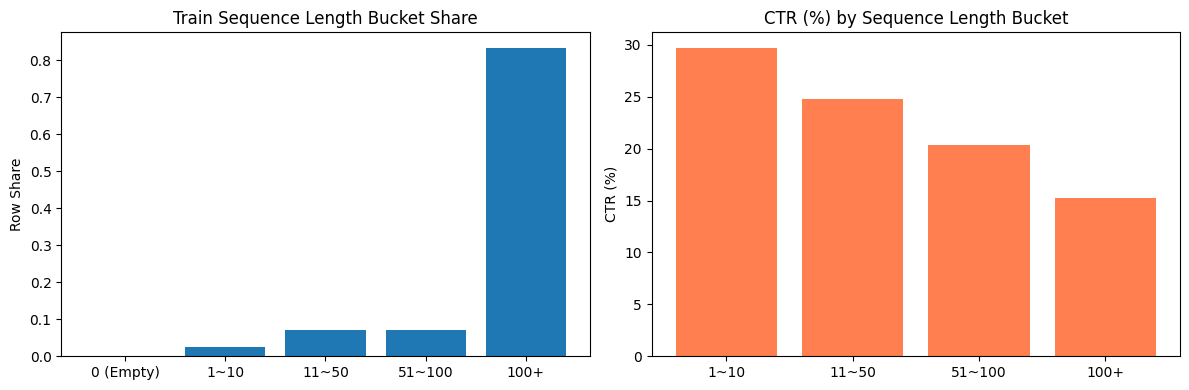

무결성 검증 완료: Train 1,225,074건 / Test 1,527,298건, 결측 0건, ID/row_id 100% 일치


In [4]:
# 3) 시퀀스 길이 구간별 CTR 분석 및 산출물 정합성(행 수, ID 순서, 결측 0건) 검증
tr_sum_df = pq.read_table(
    train_summary_out,
    columns=['row_id', 'seq_is_empty', 'seq_token_len', 'seq_unique_ratio', 'seq_recent5_unique_ratio'],
).to_pandas()
y_df = pq.read_table(train_tab_path, columns=['row_id', 'clicked']).to_pandas()
assert (tr_sum_df['row_id'].to_numpy() == y_df['row_id'].to_numpy()).all(), 'Train row_id 정렬 불일치!'

tr_sum_df['clicked'] = y_df['clicked'].to_numpy()
bins = [-1, 0, 10, 50, 100, 10_000_000]
labels = ['0 (Empty)', '1~10', '11~50', '51~100', '100+']
tr_sum_df['len_bucket'] = pd.cut(tr_sum_df['seq_token_len'], bins=bins, labels=labels)

bucket_stats = (
    tr_sum_df.groupby('len_bucket', observed=False)
    .agg(
        rows=('clicked', 'size'),
        pos_cnt=('clicked', 'sum'),
        ctr=('clicked', 'mean'),
        avg_unique_ratio=('seq_unique_ratio', 'mean'),
    )
    .reset_index()
)
bucket_stats['share'] = bucket_stats['rows'] / len(tr_sum_df)
display(bucket_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(bucket_stats['len_bucket'].astype(str), bucket_stats['share'])
axes[0].set_title('Train Sequence Length Bucket Share')
axes[0].set_ylabel('Row Share')
axes[1].bar(bucket_stats['len_bucket'].astype(str), bucket_stats['ctr'] * 100.0, color='coral')
axes[1].set_title('CTR (%) by Sequence Length Bucket')
axes[1].set_ylabel('CTR (%)')
plt.tight_layout()
plt.show()

# Test 요약 파일 ID 순서 및 결측 0건 검증
te_src_ids = pq.read_table(test_seq_path, columns=['ID']).column('ID').to_numpy()
te_sum_df = pq.read_table(test_summary_out).to_pandas()
assert len(te_sum_df) == len(te_src_ids), 'Test 요약 행 수 불일치!'
assert (te_sum_df['ID'].to_numpy() == te_src_ids).all(), 'Test ID 순서 불일치!'
assert not te_sum_df.isna().any().any(), 'Test 요약 피처에 결측치가 있습니다!'
assert not pq.read_table(train_summary_out).to_pandas().isna().any().any(), 'Train 요약 피처에 결측치가 있습니다!'
print(f'무결성 검증 완료: Train {len(tr_sum_df):,}건 / Test {len(te_sum_df):,}건, 결측 0건, ID/row_id 100% 일치')

### [해석 4] 시퀀스 길이 구간별 클릭률(CTR) 변별력 및 데이터 무결성 확인
- 시퀀스 길이(`seq_token_len`) 구간별 CTR과 고유 행동 비율(`seq_unique_ratio`) 차이를 통해 유저의 최근 활동량·다양성이 클릭 확률 예측에 유의미한 신호임을 정량 확인합니다.
- Train `row_id`(`0..N-1`) 및 Test `ID`(1,527,298건) 순서가 원천/Diet 테이블과 100% 일치하고 결측이 0건임을 검증했습니다.

### [종합 요약 및 다음 단계 안내]
- **생성된 Track A 아티팩트**:
  - `data/processed/train_seq_summary.parquet` (`row_id` + 11종 시퀀스 요약 피처)
  - `data/processed/test_seq_summary.parquet` (`ID` + 11종 시퀀스 요약 피처)
  - `reports/seq_summary_stats.json` (Train/Test 시퀀스 길이·결측률 요약)
- **GBDT 트랙 연계**: 정형 GBDT(`tabular-gbdt-engineer`) 모델에서 `row_id` / `ID` 기준으로 위 요약 피처를 즉시 Left Join해 시퀀스 길이·다양성·최근 3개 토큰 ID 신호를 활용할 수 있습니다.
- **다음 단계**: `notebooks/06_deepctr_seq_dcn_gpu.ipynb`에서 Colab GPU를 사용해 End-to-End Target-Attention + DCN-v2 5-Fold 학습을 진행합니다.